# 함정 6. 작은 lr의 QAT는 FP16 가중치로는 멈춘다

FP32 마스터와 FP16 가중치 저장을 SGD·Adam, lr {1e-4,1e-5,1e-6}에서 각각 1 epoch 비교한다. 모든 조합은 동일 시드의 float 체크포인트에서 출발한다. 연산·기울기·옵티마이저 상태·업데이트는 FP32이며 Conv/Linear 가중치의 마지막 저장 반올림만 바꾼다. BN 통계와 observer는 처음부터 동결해 가중치 저장 효과를 분리한다.

시드 0·1·2의 평균과 표준편차를 표시한다. 기본 재현 명령은 저장소에 포함된 학습 기록을 사용한다. [학습 가이드](../docs/README.md#함정-6-작은-lr의-qat는-fp16-가중치로는-멈춘다).

In [1]:
import json
import os
import platform
import time
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / 'pyproject.toml').exists() else Path.cwd().parent
RESULTS = ROOT / 'runs' / 'm3'
FIGURES = ROOT / 'docs' / 'figures'
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(RESULTS / '.matplotlib'))
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display, Markdown
plt.rcParams.update({'font.family':'DejaVu Sans','svg.fonttype':'none','svg.hashsalt':'quant-pitfalls'})
STARTED = time.perf_counter()
RUN_INFO = {'seeds':[0,1,2], 'python':platform.python_version(), 'torch':torch.__version__,
            'gpu':torch.cuda.get_device_name() if torch.cuda.is_available() else None, 'runtime_seconds':None}
INFO_HANDLE = display(RUN_INFO, display_id=True)
from quant_pitfalls.results import load_results
REPORT, DATA_SOURCE = load_results(ROOT, 'm3')
print('Training numerical input:', DATA_SOURCE)
print('Recorded training environment:', REPORT.get('reports', {}).get('float-baseline-s0', {}).get('environment'))
READY = REPORT.get('state') == 'complete'
if not READY:
    print('Selected training measurements are incomplete; plots are omitted.')

def save_figure(fig, name):
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight', metadata={'Date':None})
    fig.savefig(RESULTS / (name + '.png'), bbox_inches='tight', dpi=140)
    plt.show()

{'seeds': [0, 1, 2],
 'python': '3.11.15',
 'torch': '2.14.1+cu130',
 'gpu': 'NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU',
 'runtime_seconds': 1.488,
 'training_status': 'complete'}

Training numerical input: docs/results/m3.json.gz
Recorded training environment: {'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 5090'}


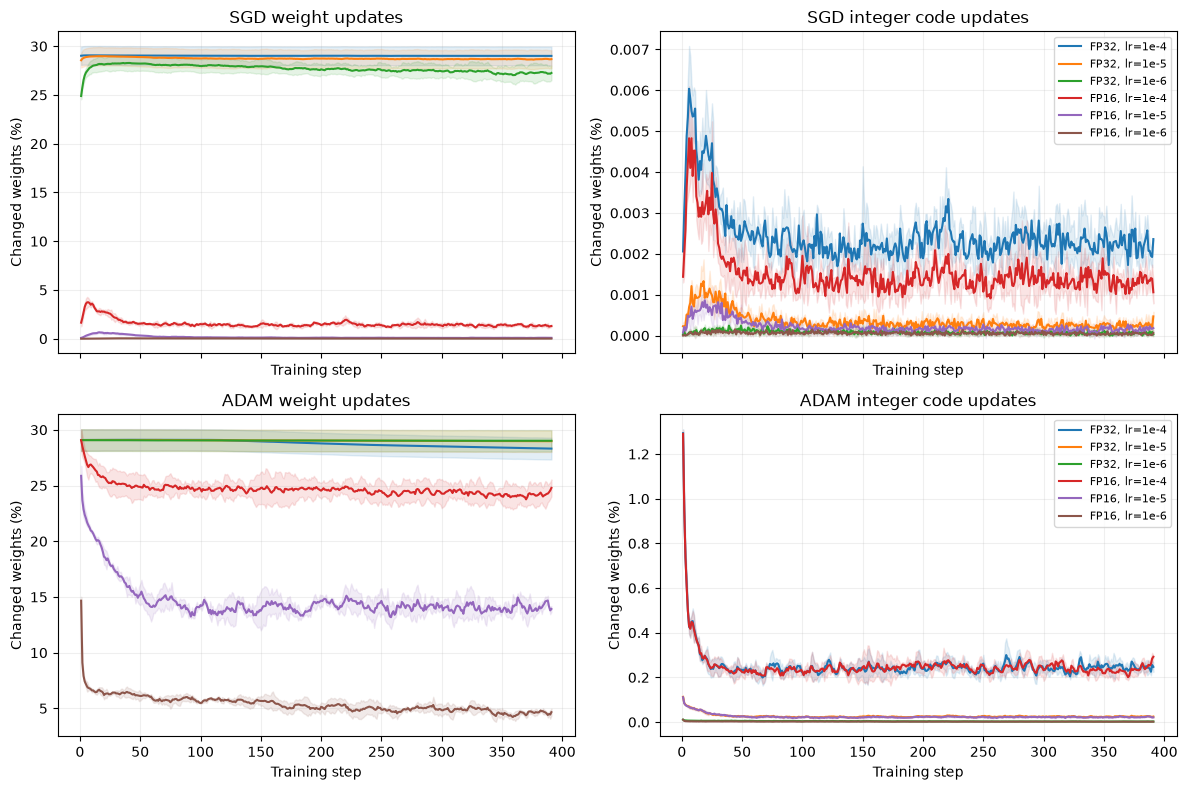

In [2]:
if READY:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
    for row, optimizer in enumerate(('sgd','adam')):
        for dtype in ('fp32','fp16'):
            for lr in ('1e-4','1e-5','1e-6'):
                runs=[REPORT['reports'][f'nb06-{dtype}-{optimizer}-lr{lr}-s{s}'] for s in (0,1,2)]
                for col, field in enumerate(('weight_change_fractions','weight_code_change_fractions')):
                    data=np.array([r['history'][0][field] for r in runs]) * 100
                    mean, std=data.mean(0),data.std(0,ddof=1)
                    x=np.arange(1,data.shape[1]+1)
                    line=axes[row,col].plot(x, mean, label=f'{dtype.upper()}, lr={lr}')[0]
                    axes[row,col].fill_between(x, mean-std,mean+std,alpha=0.12,color=line.get_color())
                    axes[row,col].set_title(optimizer.upper() + (' weight updates' if col==0 else ' integer code updates'))
                    axes[row,col].set_ylabel('Changed weights (%)')
                    axes[row,col].set_xlabel('Training step')
                    axes[row,col].grid(alpha=0.2)
        axes[row,1].legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig,'06_fp16-master-weights')

## 임계값 해석

개별 가중치의 크기와 기울기에 따라 업데이트 소실 여부가 달라진다. 평균 변경률은 이론 임계값 하나로 결정되지 않는다. 분석 모듈과 기존 테스트의 ulp 표를 함께 참고한다. Adam의 eps와 모멘트는 FP32로 유지된다.

In [3]:
RUN_INFO['runtime_seconds'] = round(time.perf_counter()-STARTED, 3)
RUN_INFO['training_status'] = REPORT['state']
INFO_HANDLE.update(RUN_INFO)

## 직접 확인하기

같은 optimizer와 같은 시드에서 lr만 다른 기록을 비교해 보자. FP16 가중치 변경률과 양자화 코드 변경률이 서로 다른 이유를 ulp와 연결해 설명하자.
